In [2]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_excel(r"..\Telco_customer_churn.xlsx")

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   str    
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   str    
 3   State              7043 non-null   str    
 4   City               7043 non-null   str    
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   str    
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   str    
 10  Senior Citizen     7043 non-null   str    
 11  Partner            7043 non-null   str    
 12  Dependents         7043 non-null   str    
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   str    
 15  Multiple Lines     7043 non-null   str    
 16  Internet Service   7043 non-null   

In [5]:
missing_values = df.isnull().sum()
missing_values = missing_values[missing_values>0].sort_values(ascending=False)
missing_values

Churn Reason    5174
dtype: int64

In [6]:
df.head()

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [7]:
df[df["Churn Value"]==1].shape

(1869, 33)

In [8]:
churn_rate = (7043 - (7043 - 1869))/7043
churn_rate

0.2653698707936959

In [9]:
df_city = df[["City","Churn Value","Churn Score"]]

In [10]:
city_summary = df_city.groupby("City").agg(
    customer_count=("Churn Value", "size"),
    churned_customers=("Churn Value", "sum"),
    churn_ratio=("Churn Value", "mean"),
)

city_summary["average_churn_score"] = (
    df_city[df_city["Churn Value"] == 1]
    .groupby("City")["Churn Score"]
    .mean()
)

city_summary = city_summary.sort_values("churn_ratio", ascending=False)

In [11]:
city_summary[city_summary["churn_ratio"]>0].sort_values(by="churn_ratio",ascending=False).head(20)

,customer_count,churned_customers,churn_ratio,average_churn_score
City,,,,
Wrightwood,4,4,1.00,77.000000
Tipton,4,4,1.00,75.250000
Truckee,4,4,1.00,89.000000
Twain,4,4,1.00,80.500000
Johannesburg,4,4,1.00,90.250000
Fort Jones,4,4,1.00,77.250000
Smith River,4,4,1.00,83.250000
Maricopa,4,4,1.00,70.750000
Boulder Creek,4,4,1.00,86.250000


In [12]:
corr_matrix = df.select_dtypes([np.number]).corr()

In [13]:
corr_matrix.columns

Index(['Count', 'Zip Code', 'Latitude', 'Longitude', 'Tenure Months',
       'Monthly Charges', 'Churn Value', 'Churn Score', 'CLTV'],
      dtype='str')

In [14]:
corr_matrix.index

Index(['Count', 'Zip Code', 'Latitude', 'Longitude', 'Tenure Months',
       'Monthly Charges', 'Churn Value', 'Churn Score', 'CLTV'],
      dtype='str')

In [15]:
corr_matrix.drop(columns="Count",inplace=True)
corr_matrix.drop("Count",axis=0,inplace=True)
corr_matrix.index

Index(['Zip Code', 'Latitude', 'Longitude', 'Tenure Months', 'Monthly Charges',
       'Churn Value', 'Churn Score', 'CLTV'],
      dtype='str')

In [16]:
#df.drop(df["Latitude","Longitude","Count"],inplace=True,errors="ignore")

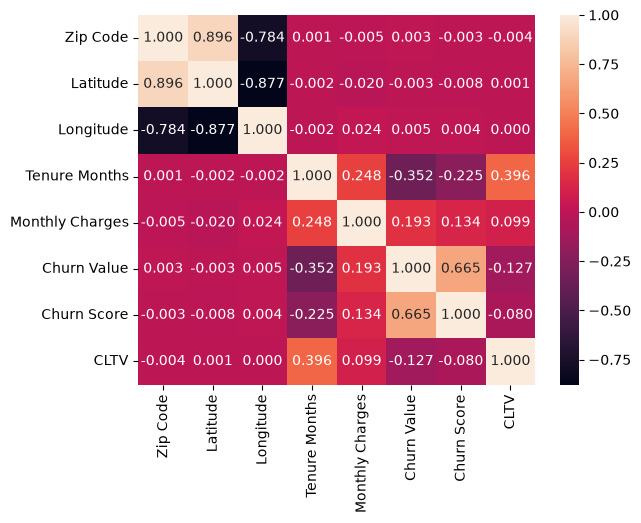

In [17]:
plt.Figure(figsize=(10,8))
sns.heatmap(data=corr_matrix,annot=True,fmt=".3f")
plt.show()

In [18]:
corr_matrix["Churn Score"]

Zip Code          -0.002769
Latitude          -0.007684
Longitude          0.004260
Tenure Months     -0.224987
Monthly Charges    0.133754
Churn Value        0.664897
Churn Score        1.000000
CLTV              -0.079782
Name: Churn Score, dtype: float64

In [19]:
corr_matrix["Churn Score"].abs()[corr_matrix["Churn Score"]<=0.05].sort_values(ascending=False).index.to_list()

['Tenure Months', 'CLTV', 'Latitude', 'Longitude', 'Zip Code']

In [20]:
True_churn_df = df[df["Churn Value"]==1]

In [21]:
df.columns

Index(['CustomerID', 'Count', 'Country', 'State', 'City', 'Zip Code',
       'Lat Long', 'Latitude', 'Longitude', 'Gender', 'Senior Citizen',
       'Partner', 'Dependents', 'Tenure Months', 'Phone Service',
       'Multiple Lines', 'Internet Service', 'Online Security',
       'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV',
       'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method',
       'Monthly Charges', 'Total Charges', 'Churn Label', 'Churn Value',
       'Churn Score', 'CLTV', 'Churn Reason'],
      dtype='str')

In [22]:
df["Online Security"].unique()

<StringArray>
['Yes', 'No', 'No internet service']
Length: 3, dtype: str

In [23]:
df["Payment Method"].unique()

<StringArray>
[             'Mailed check',          'Electronic check',
 'Bank transfer (automatic)',   'Credit card (automatic)']
Length: 4, dtype: str

In [24]:

binary_features = [col for col in df.columns if set(df[col].dropna().unique())<={"Yes","No","No internet service","No phone service"}]
binary_features

['Senior Citizen',
 'Partner',
 'Dependents',
 'Phone Service',
 'Multiple Lines',
 'Online Security',
 'Online Backup',
 'Device Protection',
 'Tech Support',
 'Streaming TV',
 'Streaming Movies',
 'Paperless Billing',
 'Churn Label']

In [25]:
True_churn_df[binary_features]

,Senior Citizen,Partner,Dependents,Phone Service,Multiple Lines,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Paperless Billing,Churn Label
0,No,No,No,Yes,No,Yes,Yes,No,No,No,No,Yes,Yes
1,No,No,Yes,Yes,No,No,No,No,No,No,No,Yes,Yes
2,No,No,Yes,Yes,Yes,No,No,Yes,No,Yes,Yes,Yes,Yes
3,No,Yes,Yes,Yes,Yes,No,No,Yes,Yes,Yes,Yes,Yes,Yes
4,No,No,Yes,Yes,Yes,No,Yes,Yes,No,Yes,Yes,Yes,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1864,No,No,No,Yes,No,No,No,No,Yes,Yes,No,Yes,Yes
1865,No,No,No,Yes,No,No,No,No,No,No,No,Yes,Yes
1866,Yes,No,No,Yes,Yes,No,No,No,No,No,No,Yes,Yes
1867,No,No,No,Yes,Yes,Yes,Yes,Yes,No,Yes,No,Yes,Yes


{'whiskers': [<matplotlib.lines.Line2D at 0x1352a264980>,
 'caps': [<matplotlib.lines.Line2D at 0x1352a264c20>,
 'boxes': [<matplotlib.lines.Line2D at 0x1352a264830>],
 'medians': [<matplotlib.lines.Line2D at 0x1352a264ec0>],
 'fliers': [<matplotlib.lines.Line2D at 0x1352a265010>],
 'means': []}

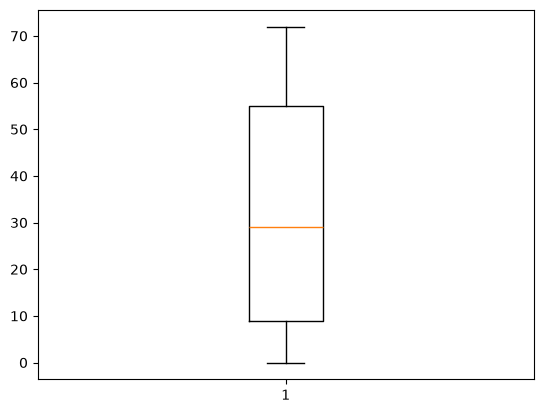

In [26]:
plt.boxplot(df["Tenure Months"])

In [27]:
df["Tenure Months"].describe()

count    7043.000000
mean       32.371149
std        24.559481
min         0.000000
25%         9.000000
50%        29.000000
75%        55.000000
max        72.000000
Name: Tenure Months, dtype: float64

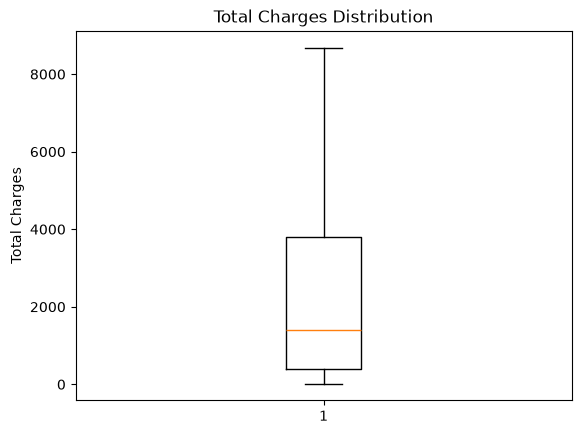

In [28]:
# Make sure the column is numeric
df["Total Charges"] = pd.to_numeric(
    df["Total Charges"].astype(str).str.replace(",", "", regex=False).str.strip(),
    errors="coerce"
)

# Drop missing values and plot
charges = df["Total Charges"].dropna()

plt.boxplot(charges)
plt.title("Total Charges Distribution")
plt.ylabel("Total Charges")
plt.show()

{'whiskers': [<matplotlib.lines.Line2D at 0x1352a3138c0>,
 'caps': [<matplotlib.lines.Line2D at 0x1352a313b60>,
 'boxes': [<matplotlib.lines.Line2D at 0x1352a313770>],
 'medians': [<matplotlib.lines.Line2D at 0x1352a313e00>],
 'fliers': [<matplotlib.lines.Line2D at 0x1352c558050>],
 'means': []}

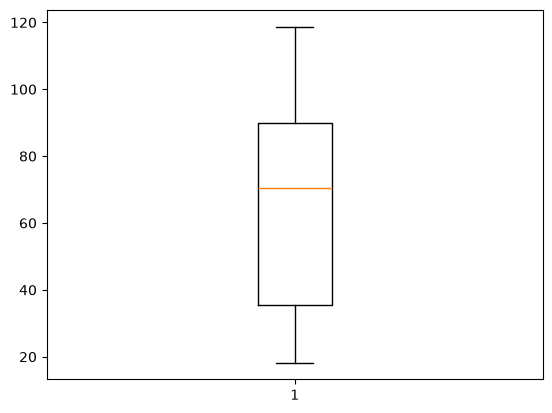

In [29]:
plt.boxplot(df["Monthly Charges"])

In [30]:

for feature in binary_features:
    df_feature = df.groupby(by=df[feature]).agg(
        category_count=("Churn Value", "size"),
        churn_ratio=("Churn Value", "mean")
    )
    df_feature["churn_ratio"]=df_feature["churn_ratio"]*100
    print(df_feature)

                category_count  churn_ratio
Senior Citizen                             
No                        5901    23.606168
Yes                       1142    41.681261
         category_count  churn_ratio
Partner                             
No                 3641    32.957979
Yes                3402    19.664903
            category_count  churn_ratio
Dependents                             
No                    5416    32.551699
Yes                   1627     6.515058
               category_count  churn_ratio
Phone Service                             
No                        682    24.926686
Yes                      6361    26.709637
                  category_count  churn_ratio
Multiple Lines                               
No                          3390    25.044248
No phone service             682    24.926686
Yes                         2971    28.609896
                     category_count  churn_ratio
Online Security                                 
No              

In [31]:
df.columns

Index(['CustomerID', 'Count', 'Country', 'State', 'City', 'Zip Code',
       'Lat Long', 'Latitude', 'Longitude', 'Gender', 'Senior Citizen',
       'Partner', 'Dependents', 'Tenure Months', 'Phone Service',
       'Multiple Lines', 'Internet Service', 'Online Security',
       'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV',
       'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method',
       'Monthly Charges', 'Total Charges', 'Churn Label', 'Churn Value',
       'Churn Score', 'CLTV', 'Churn Reason'],
      dtype='str')

In [32]:
leftovercolumns = set(df.columns) - set(binary_features)
leftovercolumns

{'CLTV',
 'Churn Reason',
 'Churn Score',
 'Churn Value',
 'City',
 'Contract',
 'Count',
 'Country',
 'CustomerID',
 'Gender',
 'Internet Service',
 'Lat Long',
 'Latitude',
 'Longitude',
 'Monthly Charges',
 'Payment Method',
 'State',
 'Tenure Months',
 'Total Charges',
 'Zip Code'}

In [33]:
categorical_features = ["Contract","Gender","Payment Method","Internet Service"]


In [34]:
for feature in categorical_features:
    df_feature = df.groupby(by=df[feature]).agg(
        category_count=("Churn Value", "size"),
        churn_ratio=("Churn Value", "mean")
    )
    df_feature["churn_ratio"]=df_feature["churn_ratio"]*100
    print(df_feature)

                category_count  churn_ratio
Contract                                   
Month-to-month            3875    42.709677
One year                  1473    11.269518
Two year                  1695     2.831858
        category_count  churn_ratio
Gender                             
Female            3488    26.920872
Male              3555    26.160338
                           category_count  churn_ratio
Payment Method                                        
Bank transfer (automatic)            1544    16.709845
Credit card (automatic)              1522    15.243101
Electronic check                     2365    45.285412
Mailed check                         1612    19.106700
                  category_count  churn_ratio
Internet Service                             
DSL                         2421    18.959108
Fiber optic                 3096    41.892765
No                          1526     7.404980


In [35]:
other_features = ["Tenure Months","Total Charges","Monthly Charges"]

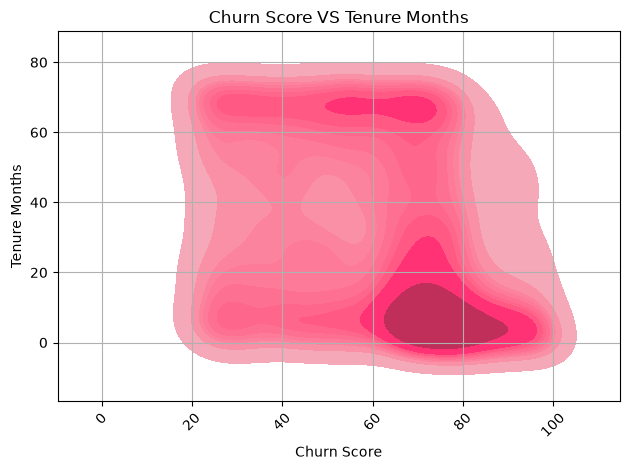

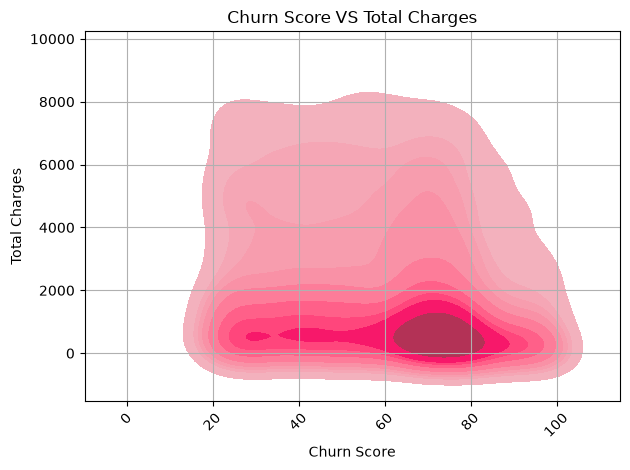

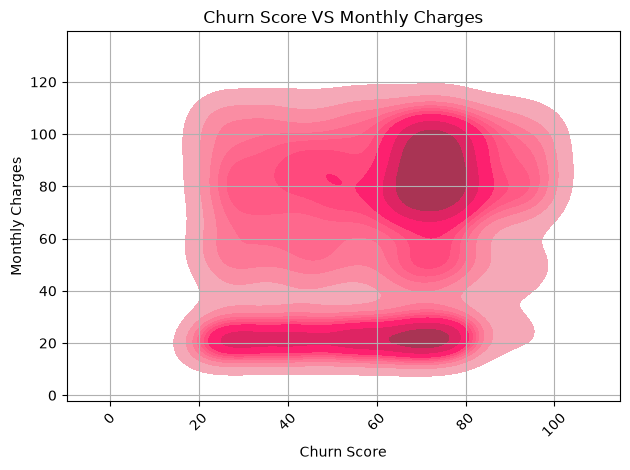

In [36]:
for feature in other_features:
    plt.Figure(figsize=(10,8))
    sns.kdeplot(data=df,x="Churn Score",y=feature,fill=True,color="pink")
    plt.title(f"Churn Score VS {feature}")
    plt.xlabel("Churn Score")
    plt.ylabel(feature)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.grid()
    plt.show()

In [40]:
True_churn_df["Tenure Months"].describe()

count    1869.000000
mean       17.979133
std        19.531123
min         1.000000
25%         2.000000
50%        10.000000
75%        29.000000
max        72.000000
Name: Tenure Months, dtype: float64

In [41]:
False_churn_df = df[df["Churn Value"]==0]

In [45]:
for i in other_features:
    print(i,":\nWhen Churn == 1:\n",True_churn_df[i].describe())
    print(f"{i}:\nWhen Churn == 0 :\n{False_churn_df[i].describe()}")
    print(f"{"=="*100}")
    

Tenure Months :
When Churn == 1:
 count    1869.000000
mean       17.979133
std        19.531123
min         1.000000
25%         2.000000
50%        10.000000
75%        29.000000
max        72.000000
Name: Tenure Months, dtype: float64
Tenure Months:
When Churn == 0 :
count    5174.000000
mean       37.569965
std        24.113777
min         0.000000
25%        15.000000
50%        38.000000
75%        61.000000
max        72.000000
Name: Tenure Months, dtype: float64
Total Charges :
When Churn == 1:
 count     1869.0
unique    1732.0
top         20.2
freq         6.0
Name: Total Charges, dtype: float64
Total Charges:
When Churn == 0 :
count    5163.000000
mean     2555.344141
std      2329.456984
min        18.800000
25%       577.825000
50%      1683.600000
75%      4264.125000
max      8672.450000
Name: Total Charges, dtype: float64
Monthly Charges :
When Churn == 1:
 count    1869.000000
mean       74.441332
std        24.666053
min        18.850000
25%        56.150000
50%      

In [46]:
True_churn_df["Total Charges"] = pd.to_numeric(True_churn_df["Total Charges"],errors="coerce")
i = "Total Charges"
print(i,":\nWhen Churn == 1:\n",True_churn_df[i].describe())
print(f"{i}:\nWhen Churn == 0 :\n{False_churn_df[i].describe()}")

Total Charges :
When Churn == 1:
 count    1869.000000
mean     1531.796094
std      1890.822994
min        18.850000
25%       134.500000
50%       703.550000
75%      2331.300000
max      8684.800000
Name: Total Charges, dtype: float64
Total Charges:
When Churn == 0 :
count    5163.000000
mean     2555.344141
std      2329.456984
min        18.800000
25%       577.825000
50%      1683.600000
75%      4264.125000
max      8672.450000
Name: Total Charges, dtype: float64


In [ ]:
i = "Churn Score"
print(i,":\nWhen Churn == 1:\n",True_churn_df[i].describe())
print(f"{i}:\nWhen Churn == 0 :\n{False_churn_df[i].describe()}")


Churn Score :
When Churn == 1:
 count    1869.000000
mean       82.510433
std        10.328570
min        65.000000
25%        74.000000
50%        82.000000
75%        91.000000
max       100.000000
Name: Churn Score, dtype: float64
Churn Score:
When Churn == 0 :
count    5174.000000
mean       50.098183
std        17.702277
min         5.000000
25%        35.000000
50%        50.000000
75%        66.000000
max        80.000000
Name: Churn Score, dtype: float64


{'whiskers': [<matplotlib.lines.Line2D at 0x1352a086ba0>,
 'caps': [<matplotlib.lines.Line2D at 0x1352a085160>,
 'boxes': [<matplotlib.lines.Line2D at 0x1352a086cf0>],
 'medians': [<matplotlib.lines.Line2D at 0x1352a0870e0>],
 'fliers': [<matplotlib.lines.Line2D at 0x1352a086f90>],
 'means': []}

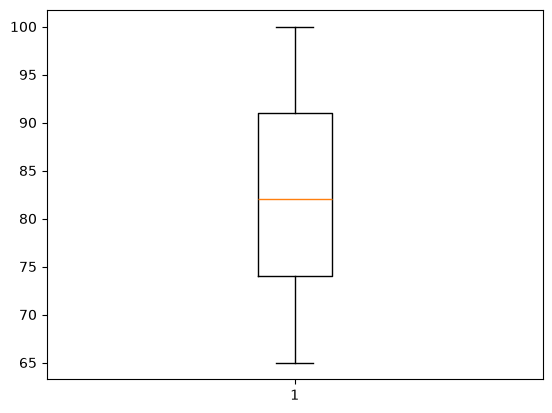

In [49]:
plt.boxplot(x=True_churn_df["Churn Score"])

{'whiskers': [<matplotlib.lines.Line2D at 0x13533410440>,
 'caps': [<matplotlib.lines.Line2D at 0x135334106e0>,
 'boxes': [<matplotlib.lines.Line2D at 0x135334102f0>],
 'medians': [<matplotlib.lines.Line2D at 0x13533410980>],
 'fliers': [<matplotlib.lines.Line2D at 0x13533410ad0>],
 'means': []}

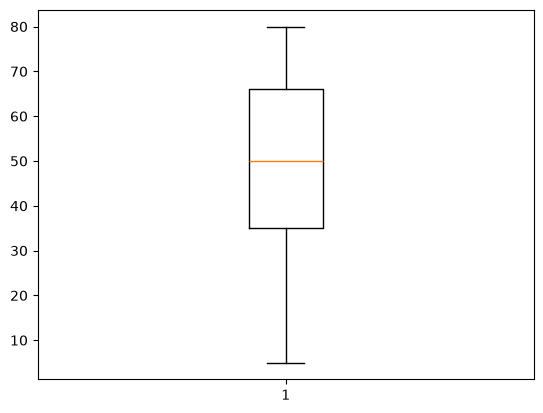

In [50]:
plt.boxplot(x=False_churn_df["Churn Score"])